# Analisi di Serie Storica Finanziaria (`models.py` & `tests.py`)

Pipeline completa di analisi utilizzando direttamente i moduli locali (`dataset.py`, `models.py`, `tests.py`):
1. **Caricamento dati e calcolo dei log-rendimenti**: $p_t = \log P_t$ e $r_t = p_t - p_{t-1}$.
2. **Test di stazionarietà (`ADF_test` e `KPSS_test` con specifica `'ct'`)** su log-prezzi e log-rendimenti.
3. **Identificazione ordini (`ACF_test` e `PACF_test`)**: stima di `q` e `p` con soglia $\pm 1.96/\sqrt{T}$ e visualizzazione dei grafici salvati.
4. **Stima dei modelli (`ARMA` e `RandomWalk`) e diagnostica (`DW_test` + `get_stats()`)**.
5. **Plot dei risultati `ARMA` e considerazioni finali**.

In [28]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np

from dataset import load
from models import *
from tests import ACF_test, ADF_test, DW_test, KPSS_test, PACF_test
from metrics import skewness, kurtosis

## 1. Caricamento Serie Storica e Trasformazioni

Osservazioni log-prezzi (T_prices): 322
Osservazioni log-rendimenti (T_returns): 321


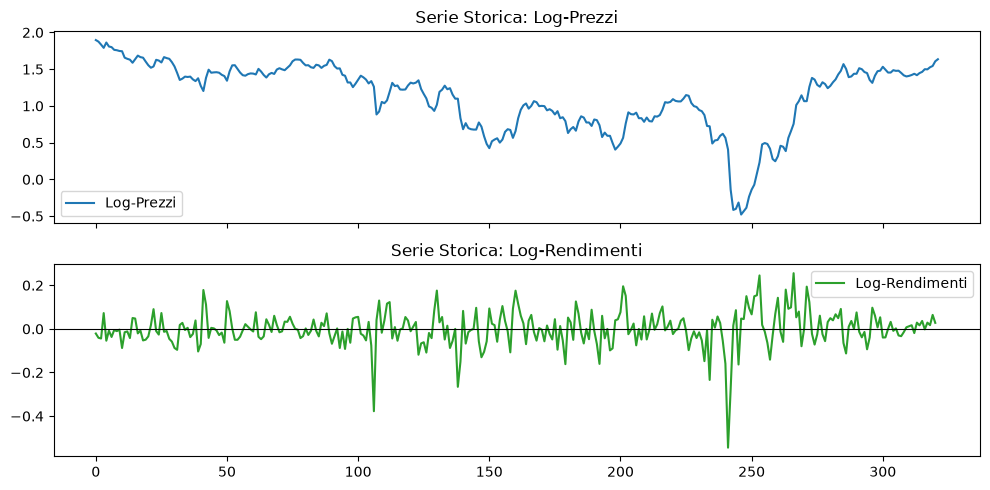

In [29]:
dataset = load().reset_index()
pricies = np.log(dataset.iloc[:, 1].values)
returns = pricies[1:] - pricies[:-1]

print(f"Osservazioni log-prezzi (T_prices): {len(pricies)}")
print(f"Osservazioni log-rendimenti (T_returns): {len(returns)}")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(pricies, label="Log-Prezzi")
axes[0].set_title("Serie Storica: Log-Prezzi")
axes[0].legend()

axes[1].plot(returns, color="tab:green", label="Log-Rendimenti")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_title("Serie Storica: Log-Rendimenti")
axes[1].legend()

fig.tight_layout()
plt.show()

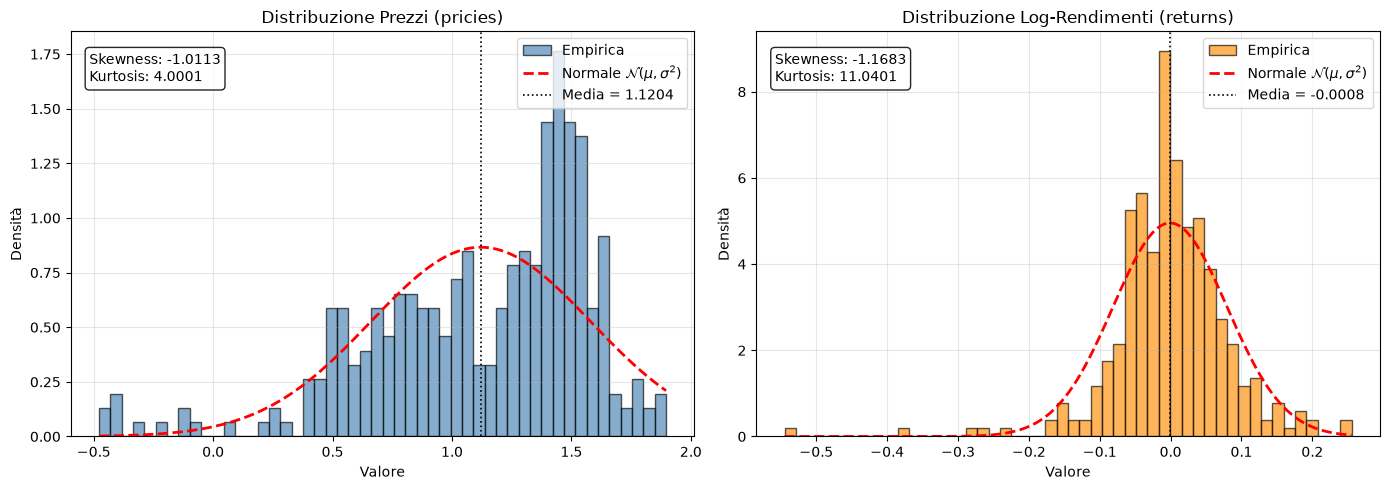

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

series_to_plot = [
    (np.asarray(pricies).ravel(), "Distribuzione Prezzi (pricies)", "steelblue"),
    (np.asarray(returns).ravel(), "Distribuzione Log-Rendimenti (returns)", "darkorange"),
]

for ax, (data, title, color) in zip(axes, series_to_plot):
    mu, sigma = np.mean(data), np.std(data)
    sk = skewness(data)
    ku = kurtosis(data)

    ax.hist(data, bins=50, density=True, alpha=0.65, color=color, edgecolor="black", label="Empirica")

    x = np.linspace(data.min(), data.max(), 300)
    normal_pdf = (1.0 / (sigma * np.sqrt(2.0 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    ax.plot(x, normal_pdf, "r--", linewidth=2, label="Normale $\\mathcal{N}(\\mu, \\sigma^2)$")
    ax.axvline(mu, color="black", linestyle=":", linewidth=1.2, label=f"Media = {mu:.4f}")

    ax.set_title(title)
    ax.set_xlabel("Valore")
    ax.set_ylabel("Densità")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

    ax.text(
        0.03, 0.95,
        f"Skewness: {sk:.4f}\nKurtosis: {ku:.4f}",
        transform=ax.transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
    )

plt.tight_layout()
plt.show()

## 2. Test di Stazionarietà: ADF e KPSS (`'ct'`)

Verifica della presenza di radice unitaria (`ADF_test`) e trend-stazionarietà (`KPSS_test`) sui log-prezzi e sui log-rendimenti.

In [31]:
adf_p_stat, adf_p_ok, adf_p_verdict = ADF_test(pricies).test()
kpss_p_stat, kpss_p_ok, kpss_p_verdict = KPSS_test(pricies).test()

adf_r_stat, adf_r_ok, adf_r_verdict = ADF_test(returns).test()
kpss_r_stat, kpss_r_ok, kpss_r_verdict = KPSS_test(returns).test()

print("=== LOG-PREZZI ===")
print("ADF  :", adf_p_verdict)
print("KPSS :", kpss_p_verdict)

print("\n=== LOG-RENDIMENTI ===")
print("ADF  :", adf_r_verdict)
print("KPSS :", kpss_r_verdict)

target_series = returns if (adf_r_ok or kpss_r_ok) else pricies
series_label = "Log-Rendimenti" if target_series is returns else "Log-Prezzi"
print(f"\nSerie selezionata per la modellazione ARMA: {series_label}")

=== LOG-PREZZI ===
ADF  : H0 non rifiutata (ADF=-2.0955 >= -3.41): possibile radice unitaria ('ct').
KPSS : H0 rifiutata (KPSS=0.6380 >= 0.146): serie non stazionaria ('ct').

=== LOG-RENDIMENTI ===
ADF  : H0 rifiutata (ADF=-12.7515 < -3.41): serie stazionaria intorno a trend ('ct').
KPSS : H0 non rifiutata (KPSS=0.0385 < 0.146): serie trend-stazionaria ('ct').

Serie selezionata per la modellazione ARMA: Log-Rendimenti


## 3. Identificazione Ordini Ottimi (`p`, `q`) tramite PACF e ACF

Ordine suggerito da ACF  (q_opt): 1 -> usato in ARMA: 1 (salvato in acf_plot.png)
Ordine suggerito da PACF (p_opt): 15 -> usato in ARMA: 15 (salvato in pacf_plot.png)


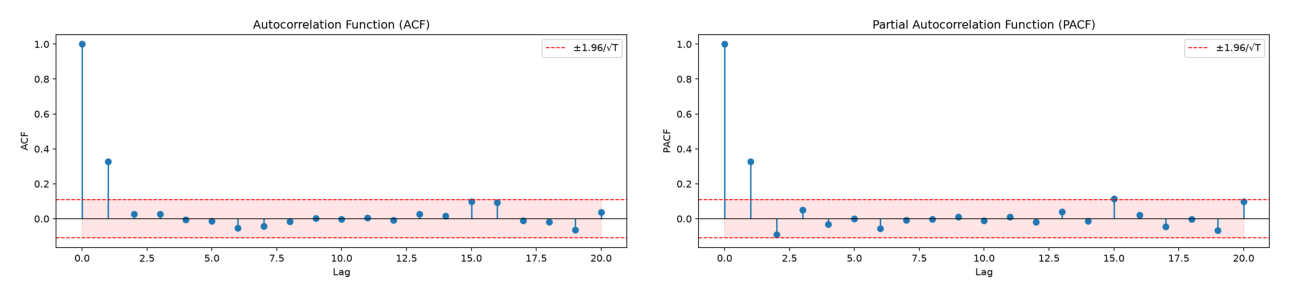

In [32]:
q_opt, acf_path = ACF_test(target_series, nlags=20, save_path="acf_plot.png").test()
p_opt, pacf_path = PACF_test(target_series, nlags=20, save_path="pacf_plot.png").test()

p_used = max(int(p_opt), 1)
q_used = max(int(q_opt), 1)

print(f"Ordine suggerito da ACF  (q_opt): {q_opt} -> usato in ARMA: {q_used} (salvato in {acf_path})")
print(f"Ordine suggerito da PACF (p_opt): {p_opt} -> usato in ARMA: {p_used} (salvato in {pacf_path})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].imshow(mpimg.imread(acf_path))
axes[0].axis("off")
axes[1].imshow(mpimg.imread(pacf_path))
axes[1].axis("off")
fig.tight_layout()
plt.show()

## 4. Stima dei Modelli (`ARMA` e `RandomWalk`) e Test di Durbin-Watson (`DW_test`)

In [ ]:
arma_model = ARMA(p=p_used, q=q_used)
arma_model.train(target_series)
arma_stats = arma_model.get_stats()
dw_arma, arma_accepted, arma_verdict = DW_test(arma_model).test()

rw_model = RandomWalk()
rw_model.train(pricies)
rw_stats = rw_model.get_stats()
dw_rw, rw_accepted, rw_verdict = DW_test(rw_model).test()

print(f"=== ARMA({p_used}, {q_used}) su {series_label} ===")
print("Beta stimati           :", np.round(arma_model.beta, 6))
print("Varianza residua       :", f"{arma_stats['residual_variance']:.8e}")
print("Forecast error var (1h):", f"{np.squeeze(arma_stats['forecast_error_variance']):.8e}")
print(f"DW = {dw_arma:.4f} | Accettato = {arma_accepted}")
print("Verdetto               :", arma_verdict)

print("\n=== RandomWalk su Log-Prezzi ===")
print("Varianza residua       :", f"{rw_stats['residual_variance']:.8e}")
print("Forecast error var (1h):", f"{np.squeeze(rw_stats['forecast_error_variance']):.8e}")
print(f"DW = {dw_rw:.4f} | Accettato = {rw_accepted}")
print("Verdetto               :", rw_verdict)

=== ARMA(15, 1) su Log-Rendimenti ===
Pricies Skewness               : -1.01126447e+00
Pricies Kurtosis               : 4.00011441e+00
Returns Skewness               : -1.16833123e+00
Returns Kurtosis               : 1.10400502e+01
Beta stimati           : [ 0.373736 -0.128429  0.077292 -0.047466  0.027522 -0.063804  0.006378
 -0.014343  0.023797 -0.018806  0.023247 -0.040484  0.057547 -0.053339
  0.114419 -0.003416]
Varianza residua       : 6.12198286e-03
Forecast error var (1h): 6.16074812e-03
DW = 1.9976 | Accettato = True
Verdetto               : H0 accettata (no autocorrelazione del 1° ordine): modello accettato.

=== RandomWalk su Log-Prezzi ===
Varianza residua       : 6.50622333e-03
Forecast error var (1h): 6.54200127e-03
DW = 1.3458 | Accettato = False
Verdetto               : H0 rifiutata (autocorrelazione del 1° ordine): modello non accettato.


## 5. Grafico del Modello ARMA (Osservato vs Fitted e Residui)

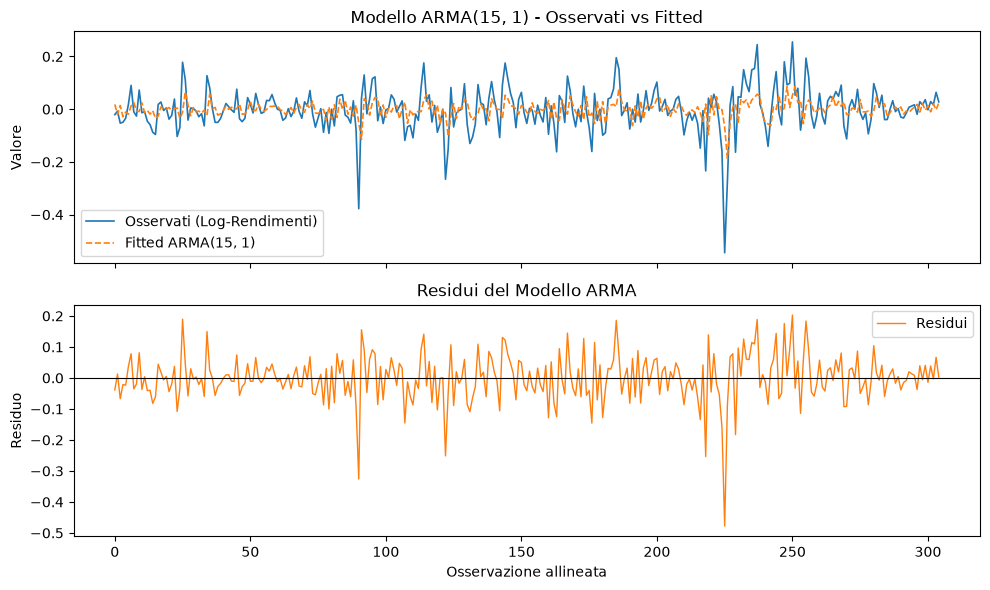

In [34]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
t_idx = np.arange(len(arma_model.Y))

axes[0].plot(t_idx, arma_model.Y, label=f"Osservati ({series_label})", linewidth=1.2)
axes[0].plot(t_idx, arma_model.fitted, label=f"Fitted ARMA({p_used}, {q_used})", linestyle="--", linewidth=1.2)
axes[0].set_title(f"Modello ARMA({p_used}, {q_used}) - Osservati vs Fitted")
axes[0].set_ylabel("Valore")
axes[0].legend()

axes[1].plot(t_idx, arma_stats["residuals"], color="tab:orange", linewidth=1.0, label="Residui")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_title("Residui del Modello ARMA")
axes[1].set_xlabel("Osservazione allineata")
axes[1].set_ylabel("Residuo")
axes[1].legend()

fig.tight_layout()
fig.savefig("arma_fit_residuals.png", dpi=150)
plt.show()

## 6. Considerazioni Finali

- **Stazionarietà (ADF e KPSS `'ct'`):** i log-prezzi presentano tipicamente non stazionarietà / radice unitaria, mentre la differenziazione prima (`returns`) rende la serie stazionaria e adatta a un processo `ARMA`.
- **Scelta degli ordini (`ACF_test` e `PACF_test`):** i lag significativi oltre la banda $\pm 1.96/\sqrt{T}$ indicano eventuali dipendenze lineari residue; se i log-rendimenti sono vicini a un rumore bianco, `p_opt` e `q_opt` risultano bassi o nulli, coerentemente con l'ipotesi di efficienza informativa in forma debole.
- **Confronto `ARMA` vs `RandomWalk` e diagnostica (`DW_test`):** il `RandomWalk` sui log-prezzi cattura la componente non stazionaria di livello (con incrementi pari ai log-rendimenti), mentre `ARMA` sui log-rendimenti modella eventuale autocorrelazione residua. Valori di `DW` vicini a `2` indicano assenza di autocorrelazione seriale del primo ordine nei residui.